# INTRODUCCION A SERIES DE TIEMPO


In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats


In [21]:

##Importar data
data = pd.read_csv('index2018.csv')
df= data.copy()

In [3]:
#informacion base 
df.set_index('date', inplace=True)
df.head()

,spx,dax,ftse,nikkei
date,,,,
07/01/1994,469.90,2224.95,3445.98,18124.01
10/01/1994,475.27,2225.00,3440.58,18443.44
11/01/1994,474.13,2228.10,3413.77,18485.25
12/01/1994,474.17,2182.06,3372.02,18793.88
13/01/1994,472.47,2142.37,3360.01,18577.26


In [4]:
#Valores faltantes

df.asfreq('b')

,spx,dax,ftse,nikkei
date,,,,
1996-01-01,NaN,NaN,NaN,NaN
1996-01-02,NaN,NaN,NaN,NaN
1996-01-03,NaN,NaN,NaN,NaN
1996-01-04,NaN,NaN,NaN,NaN
1996-01-05,NaN,NaN,NaN,NaN
...,...,...,...,...
2015-12-25,NaN,NaN,NaN,NaN
2015-12-28,NaN,NaN,NaN,NaN
2015-12-29,NaN,NaN,NaN,NaN


In [5]:
df.spx = df.spx.ffill()
df.ftse = df.ftse.bfill()
df.dax = df.dax.fillna(value = df.dax.mean())
df.nikkei = df.nikkei.bfill()



In [6]:
df.isnull().sum()

spx       0
dax       0
ftse      0
nikkei    0
dtype: int64

In [7]:
df['market_value'] = df.spx 
del df['dax']
del df['nikkei']
del df['ftse']
del df['spx']
df.head()

,market_value
date,
07/01/1994,469.90
10/01/1994,475.27
11/01/1994,474.13
12/01/1994,474.17
13/01/1994,472.47


In [8]:
size = int(len(df) * 0.8)
train = df.iloc[:size]
test = df.iloc[size:]

In [9]:
train.tail(5)

,market_value
date,
28/03/2013,1569.185872
29/03/2013,1569.185872
01/04/2013,1562.173837
02/04/2013,1570.252238
03/04/2013,1553.686978


In [10]:
## Descriptivo

df.describe()

,market_value
count,6269.000000
mean,1288.127542
std,487.586473
min,438.920000
25%,990.671905
50%,1233.420000
75%,1459.987747
max,2872.867839


# Ruido Blanco 


In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import statsmodels.graphics.tsaplots as sgt
import statsmodels.tsa.stattools as sts
from statsmodels.tsa.seasonal import seasonal_decompose
import seaborn as sns
sns.set()


In [12]:
data = pd.read_csv('Index2018.csv')
df = data.copy()

df.date = pd.to_datetime(df.date, dayfirst=True)
df.set_index('date', inplace=True)
df= df.asfreq('b')
df= df.ffill()
df['market_value'] = df.spx
del df['spx']
del df['dax']
del df['ftse']
del df['nikkei']
size = int(len(df) * 0.8)
train, test = df.iloc[:size], df.iloc[size:]

In [13]:
wn = np.random.normal(loc=train.market_value.mean()
                      , scale=train.market_value.std(),
                        size=len(train))

In [14]:
train = train.copy()
train['wn'] = wn
train.head()

,market_value,wn
date,,
1994-01-07,469.90,1452.842371
1994-01-10,475.27,539.834064
1994-01-11,474.13,1421.172187
1994-01-12,474.17,1138.985931
1994-01-13,472.47,792.132546


In [15]:
train.describe()

,market_value,wn
count,5021.000000,5021.000000
mean,1091.651926,1087.461715
std,292.559287,290.198202
min,438.920000,-5.823780
25%,914.620000,898.179351
50%,1144.650000,1087.886737
75%,1316.280729,1274.974962
max,1570.252238,2214.561034


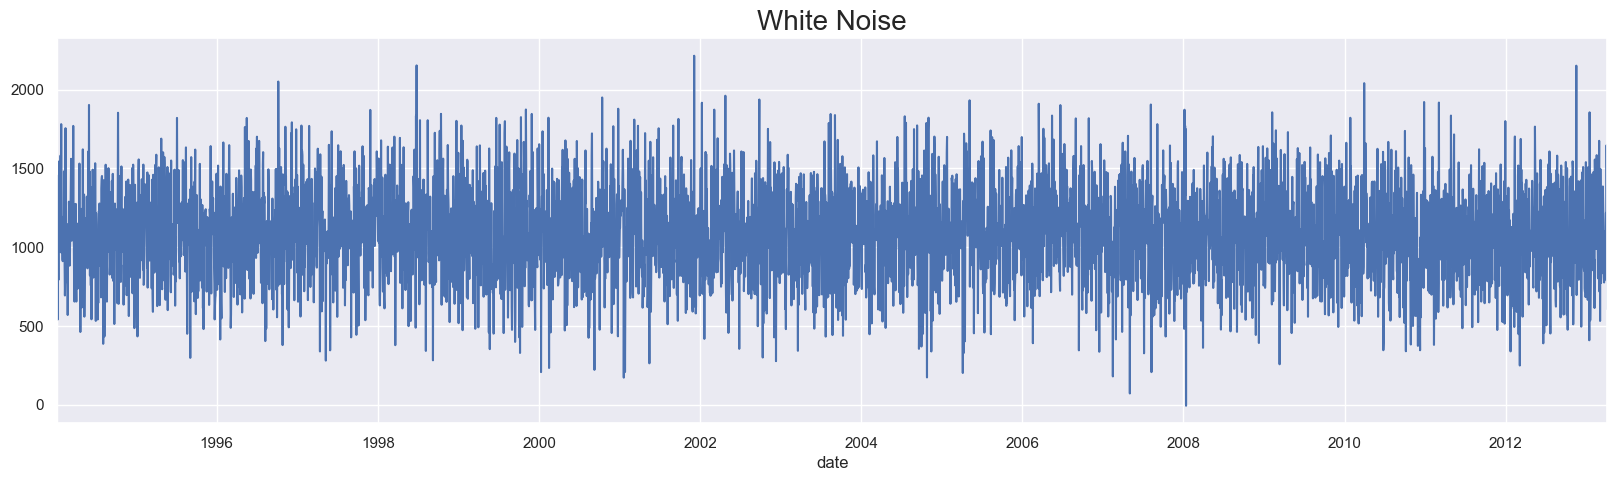

In [16]:
train.wn.plot(figsize=(20,5))
plt.title('White Noise',size=20)
plt.show()

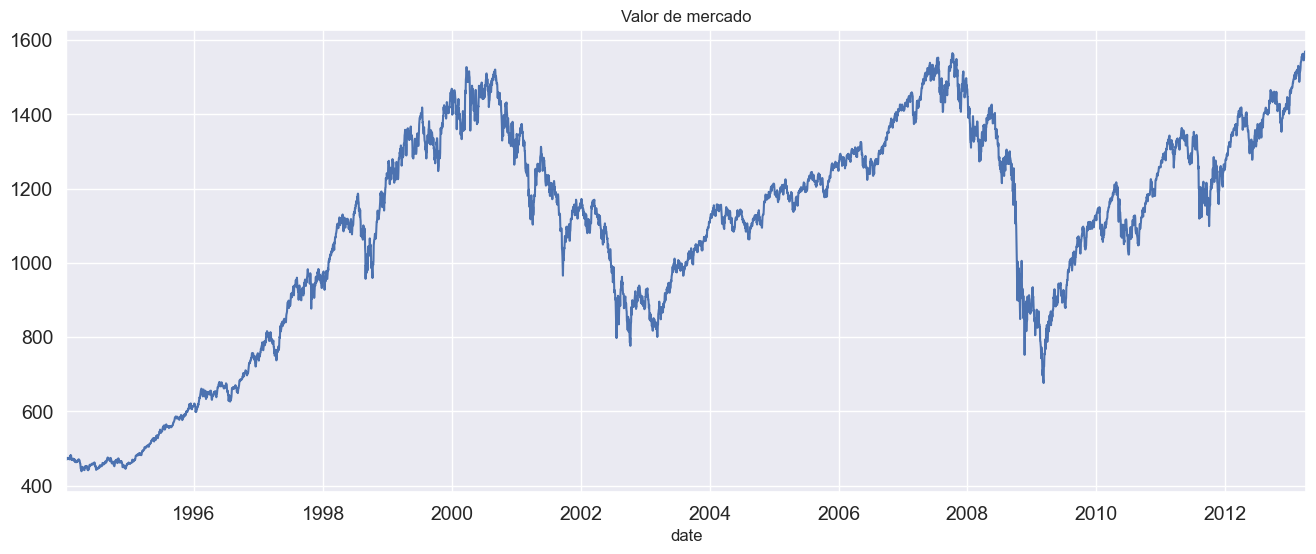

In [17]:
train.market_value.plot(figsize=(16,6), title='Valor de mercado', fontsize=14)

plt.show()

In [18]:
df = pd.to_datetime(df, dayfirst=True)

ValueError: to assemble mappings requires at least that [year, month, day] be specified: [day,month,year] is missing

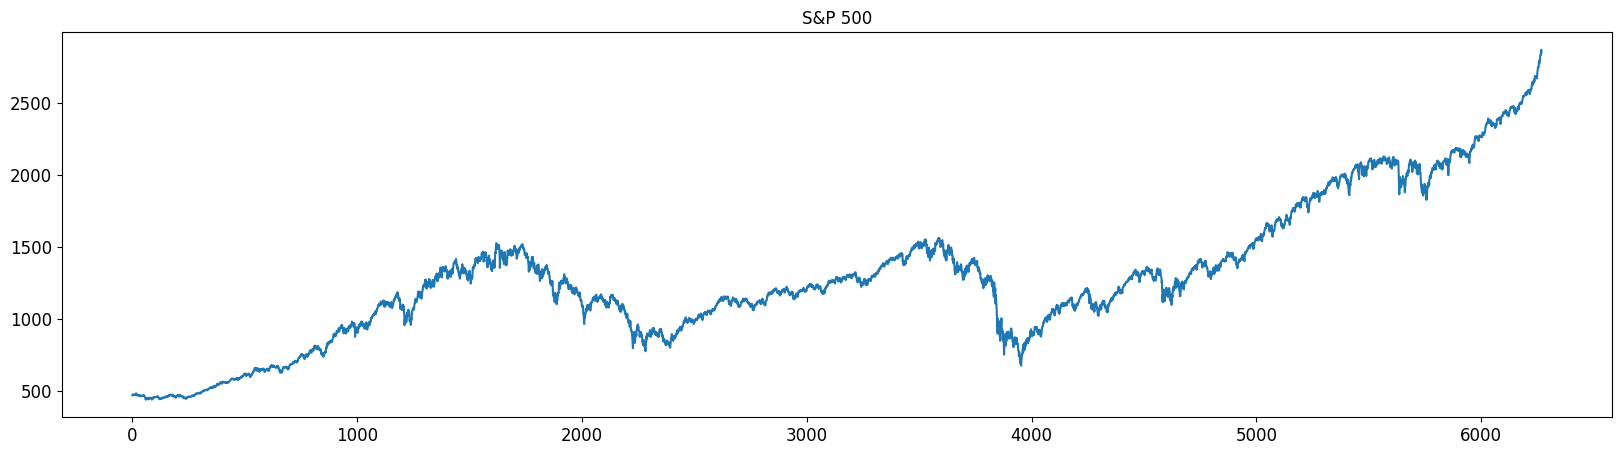

In [ ]:
## Grafica de lineas de las variables de la bolsa de valores 

df.spx.plot(figsize = (20,5), title = 'S&P 500', fontsize = 12)
plt.show()   

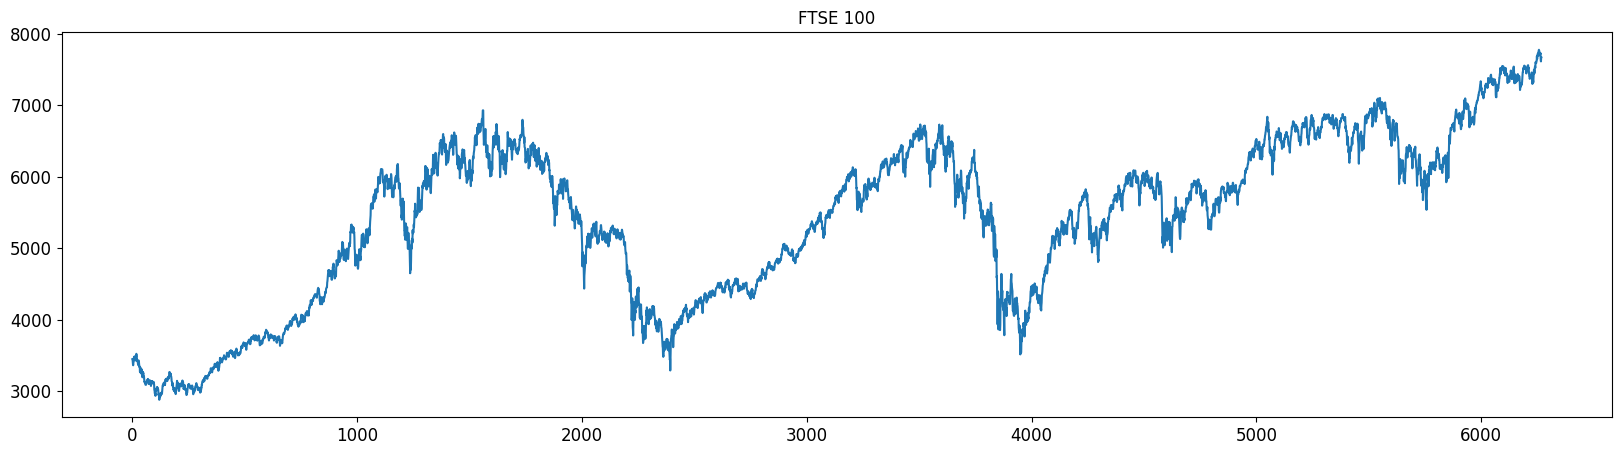

In [ ]:
df.ftse.plot(figsize = (20,5), title = 'FTSE 100', fontsize = 12)
plt.show()   

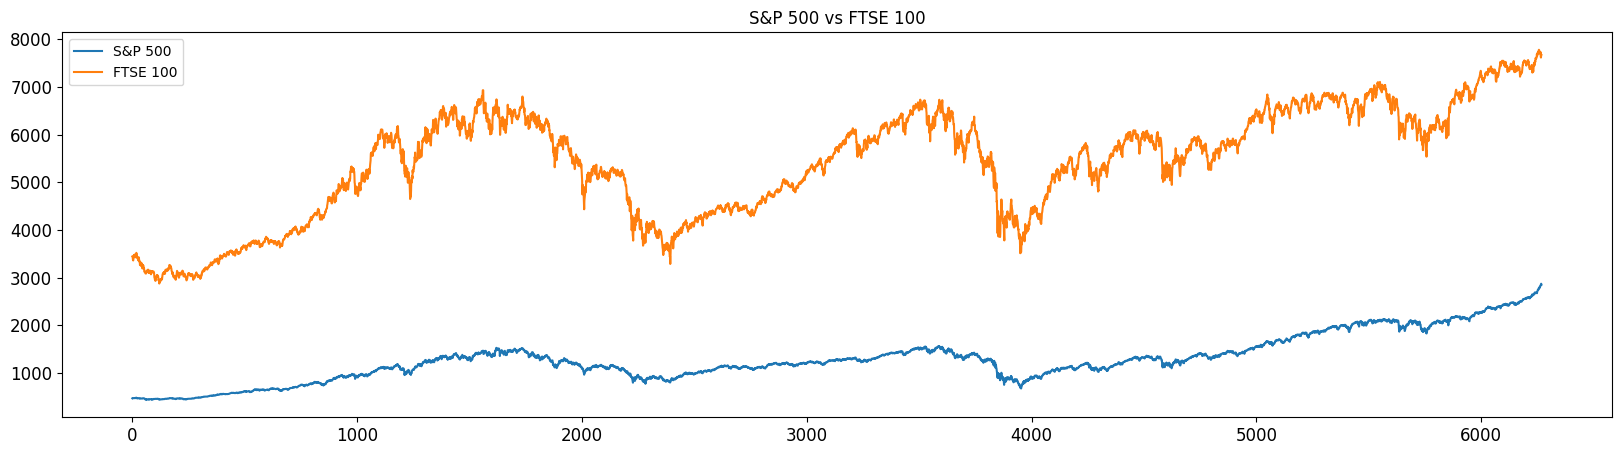

In [ ]:
df.spx.plot(figsize = (20,5), title = 'S&P 500', fontsize = 12)
df.ftse.plot(figsize = (20,5), title = 'FTSE 100', fontsize = 12)
plt.legend(['S&P 500', 'FTSE 100'])
plt.title('S&P 500 vs FTSE 100')
plt.show()




In [ ]:
stats.pearsonr(df.spx, df.ftse)

AttributeError: 'DataFrame' object has no attribute 'spx'

In [ ]:
datos = df.spx

# Calcular media y desviación estándar muestral
mu = np.mean(datos)
sigma = np.std(datos, ddof=1)

# Prueba Kolmogorov-Smirnov contra N(mu, sigma)
stat, p_valor = stats.kstest(datos, 'norm', args=(mu, sigma))

print("Estadístico KS:", stat)
print("p-valor:", p_valor)

alpha = 0.05
if p_valor > alpha:
    print("No se rechaza la normalidad (los datos parecen normales).")
else:
    print("Se rechaza la normalidad (los datos no parecen normales).")

Estadístico KS: 0.11295458245329948
p-valor: 3.968884436490641e-70
Se rechaza la normalidad (los datos no parecen normales).


# Ejemplo 


In [2]:
import pandas as pd 
import matplotlib.pyplot as plt
import numpy as np
import statsmodels.graphics.tsaplots as sgt
import statsmodels.tsa.stattools as sts
import statsmodels.tsa.seasonal as sts2
import seaborn as sns
sns.set()

In [ ]:
data = pd.read_csv('index2018.csv')
df= data.copy()
df.date= pd.to_datetime(df.date, dayfirst=True)
df.set_index('date', inplace=True)
df = df.asfreq('b')
df = df.ffill()
df['market_value'] = df.spx
del df['dax']
del df['nikkei']
del df['ftse']
del df['spx']
size = int(len(df) * 0.8)
train,test = df.iloc[:size], df.iloc[size:]

In [ ]:
## Calculamos el retorno 
train['returns'] = train.market_value.pct_change()
train = train.dropna(subset=['returns'])
train.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 5018 entries, 1994-01-12 to 2013-04-05
Freq: B
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   market_value  5018 non-null   float64
 1   returns       5018 non-null   float64
dtypes: float64(2)
memory usage: 117.6 KB


In [ ]:
np.random.seed(42)
wn = np.random.normal(loc=0,
                       scale=train.returns.std(),
                         size=len(train))
train.loc[:,'wn'] = wn


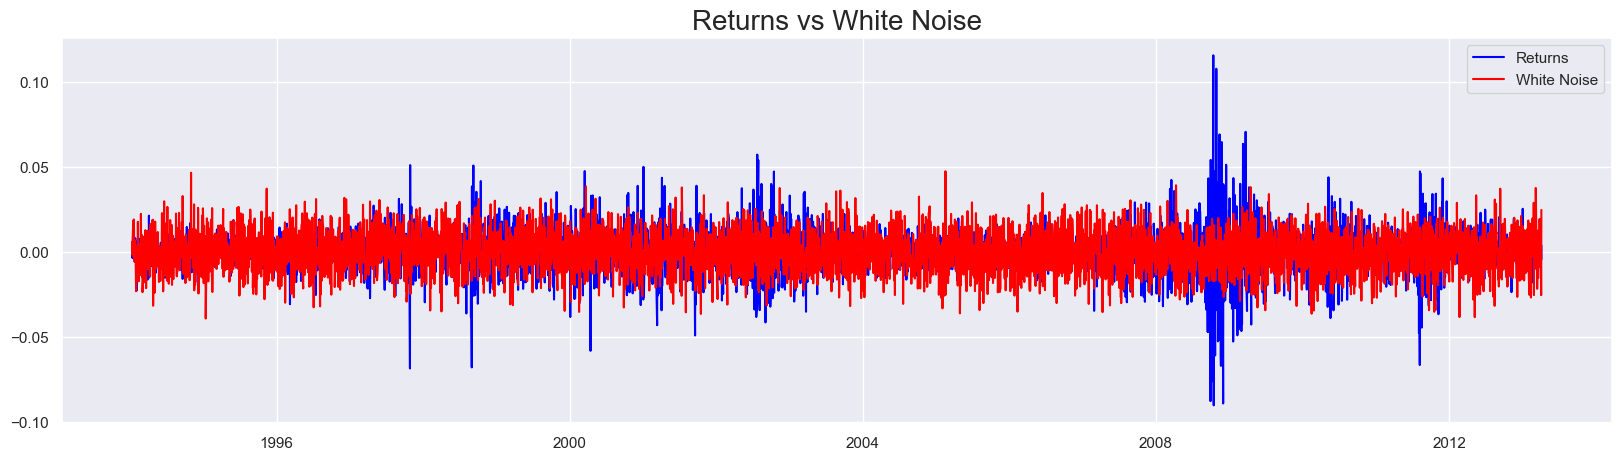

In [ ]:
plt.figure(figsize=(20,5))
plt.plot(train.returns, color='blue', label='Returns')
plt.plot(train.wn, color='red', label='White Noise')
plt.legend()
plt.title('Returns vs White Noise', size=20)
plt.show()



In [ ]:
np.random.seed(42)
train['random_walk'] = train.loc[:,'market_value'].iloc[0]*np.exp(np.cumsum(train.loc[:,'wn']))


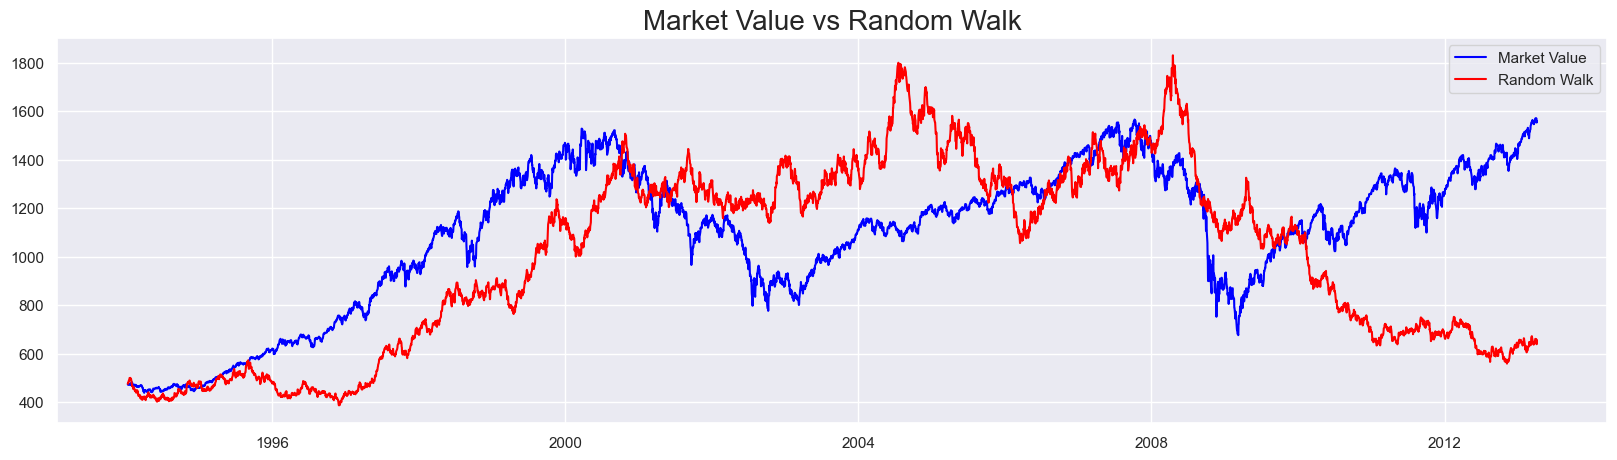

In [ ]:
plt.figure(figsize=(20,5))
plt.plot(train.market_value, color='blue', label='Market Value')
plt.plot(train.random_walk, color='red', label='Random Walk')
plt.legend()
plt.title('Market Value vs Random Walk', size=20)
plt.show()

In [ ]:
# Estacionareidad de la serie de tiempo

sts.adfuller(train.market_value)
sts.adfuller(train.returns)
sts.adfuller(train.wn)
sts.adfuller(train.random_walk)

(np.float64(-1.4402531346869005),
 np.float64(0.5628334734661404),
 0,
 5017,
 {'1%': np.float64(-3.431654095870046),
  '5%': np.float64(-2.8621162697870046),
  '10%': np.float64(-2.5670767490325597)},
 np.float64(39703.9460575844))

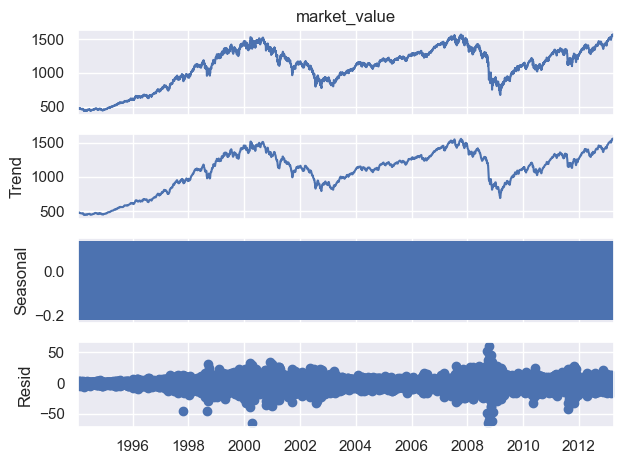

In [ ]:
# Estacionareidad de la serie de tiempo
s_des_asit= seasonal_decompose(train.market_value,model='additive')
s_des_asit.plot()
plt.show()


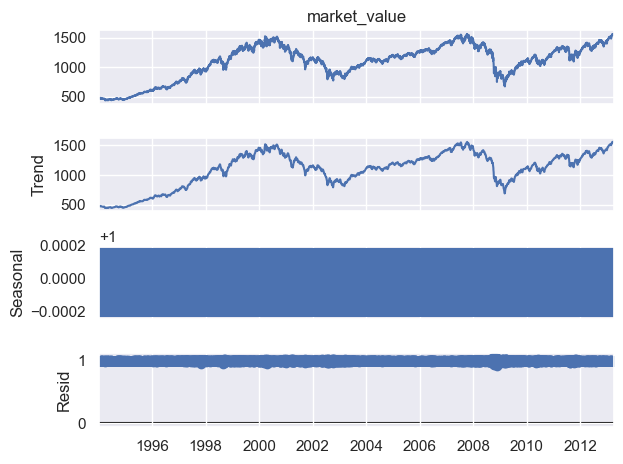

In [ ]:
s_des_asit2= seasonal_decompose(train.market_value,model='multiplicative')
s_des_asit2.plot()
plt.show()

# otro ejemplo de descomposicion 


In [11]:
airline = pd.read_csv("airline_passengers.csv", index_col="Month", parse_dates=True)


airline.head()


FileNotFoundError: [Errno 2] No such file or directory: 'airline_passengers.csv'

In [4]:
plt.figure(figsize=(20,5))
plt.plot(airline, color='blue', label='Airline Passengers')
plt.xlabel('Date')
plt.ylabel('Number of Passengers')
plt.show()

NameError: name 'airline' is not defined

<Figure size 2000x500 with 0 Axes>

In [5]:
sts.adfuller(airline.dropna().values)

NameError: name 'airline' is not defined